<h2>IS453 Financial Analytics</h2><h2>Group Assignment - Home Improvement Loan Scorecard</h2>

### Step 2: Merged Data

This notebook follows `00_Customer_Segmentation.ipynb` and `01_flattened_Bureau_data.ipynb`. It merges the two outputs, runs a diagnostic EDA and engineers financially meaningful characteristics.

Scope: no imputation, outlier capping, feature removal, `TARGET`-based selection, WOE/IV, train/test split or modelling.

## 2.1 Business Context and Objectives

We are developing a credit scorecard for **Home Improvement Loans**. In Step 0 the customer population was defined with three eligibility criteria:

1. Owns residential property: `FLAG_OWN_REALTY = 'Y'`
2. Is at least 18 years old
3. Has positive reported income: `AMT_INCOME_TOTAL > 0`

These are **business assumptions** for selecting a plausible Home Improvement Loan population, not confirmed renovation-loan purposes.

In Step 1 the Bureau Data was flattened from many credit records per applicant to one applicant-level record.

This notebook combines both sources into one view of each applicant's:

- financial capacity (income, household size)
- employment stability
- existing debt obligations (bureau debt)
- repayment commitments (instalment on the requested loan)
- previous credit behaviour (delinquency, history length)
- housing and property characteristics

Raw attributes alone can mislead: a debt of 500,000 means something very different for an applicant earning 100,000 than for one earning 1,000,000. Feature engineering therefore turns raw amounts into **ratios and measures with a direct financial interpretation**, such as debt relative to income.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# show more columns and format floats for readability
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:,.4f}'.format)

## 2.2 Load and Validate Input Datasets

**Input file names.** The brief lists the inputs as `home_improvement_segement.csv` and `flattened_Bureau_Data.csv`. The files actually produced by Steps 0 and 1 are `home_improvement_segment.csv` and `01_flattened_Bureau_data.csv`, so those exact names are used below. If either file is missing the notebook stops with an error rather than substituting another file (for example, it does **not** fall back to `01_Bureau_Features_Full.csv`).

In [2]:
# input files produced by Step 0 and Step 1
application_path = 'data/home_improvement_segment.csv'
bureau_path = 'data/01_flattened_Bureau_data.csv'
dict_path = 'data/raw/IS453 Group Assignment - Data Dict.xlsx'

for path in [application_path, bureau_path, dict_path]:
    if not os.path.exists(path):
        raise FileNotFoundError(f'Required input file not found: {path}. Run the earlier step that creates it.')

application_df = pd.read_csv(application_path)
bureau_df = pd.read_csv(bureau_path)
app_dict = pd.read_excel(dict_path, sheet_name='Application Data')

# keep an untouched copy of the IDs and TARGET for later comparison
# (application_df itself is never modified, so it serves as the reference for all other columns)
target_orig = application_df[['SK_ID_CURR', 'TARGET']].copy()

print('Application data:', application_df.shape)
print('Bureau data:     ', bureau_df.shape)

Application data: (213312, 120)
Bureau data:      (181841, 24)


In [3]:
# key structure of both datasets
def id_summary(df):
    return [len(df), df.shape[1], df['SK_ID_CURR'].nunique(),
            df['SK_ID_CURR'].duplicated().sum(), df['SK_ID_CURR'].isnull().sum()]

id_table = pd.DataFrame({
    'Application Data': id_summary(application_df),
    'Bureau Data': id_summary(bureau_df),
}, index=['Number of rows', 'Number of columns', 'Unique SK_ID_CURR', 'Duplicate SK_ID_CURR', 'Missing SK_ID_CURR'])
id_table.index.name = 'Metric'
id_table.style.format('{:,.0f}')

,Application Data,Bureau Data
Metric,,
Number of rows,"213,312","181,841"
Number of columns,120,24
Unique SK_ID_CURR,"213,312","181,841"
Duplicate SK_ID_CURR,0,0
Missing SK_ID_CURR,0,0


In [4]:
# required checks before merging
overlap_cols = sorted((set(application_df.columns) & set(bureau_df.columns)) - {'SK_ID_CURR'})

checks = {
    '1. SK_ID_CURR in both datasets': 'SK_ID_CURR' in application_df.columns and 'SK_ID_CURR' in bureau_df.columns,
    '2. No missing applicant IDs': application_df['SK_ID_CURR'].notnull().all() and bureau_df['SK_ID_CURR'].notnull().all(),
    '3. SK_ID_CURR unique in both': application_df['SK_ID_CURR'].is_unique and bureau_df['SK_ID_CURR'].is_unique,
    '4. Compatible ID data types': application_df['SK_ID_CURR'].dtype == bureau_df['SK_ID_CURR'].dtype,
    '5. No overlapping non-key columns': len(overlap_cols) == 0,
    '6. TARGET in Application Data': 'TARGET' in application_df.columns,
    '7. TARGET not in Bureau Data': 'TARGET' not in bureau_df.columns,
    '8. No duplicate column names': application_df.columns.is_unique and bureau_df.columns.is_unique,
}
for name, result in checks.items():
    print(f'{name}: {result}')
print('\nID data types:', application_df['SK_ID_CURR'].dtype, '/', bureau_df['SK_ID_CURR'].dtype)
print('Overlapping non-key columns:', overlap_cols if overlap_cols else 'none')
print('Bureau IDs not in the application segment:', (~bureau_df['SK_ID_CURR'].isin(application_df['SK_ID_CURR'])).sum())

# stop if the one-row-per-applicant structure is violated
if not all(checks.values()):
    raise ValueError('Input validation failed - see the checks above. Duplicates are not dropped automatically.')

1. SK_ID_CURR in both datasets: True
2. No missing applicant IDs: True
3. SK_ID_CURR unique in both: True
4. Compatible ID data types: True
5. No overlapping non-key columns: True
6. TARGET in Application Data: True
7. TARGET not in Bureau Data: True
8. No duplicate column names: True

ID data types: int64 / int64
Overlapping non-key columns: none
Bureau IDs not in the application segment: 0


Both inputs have exactly one row per `SK_ID_CURR`, no missing IDs, matching integer ID types and no overlapping column names, so the merge cannot overwrite or duplicate anything. `TARGET` exists only in the application data. It is carried through unchanged and **is not used** in any feature calculation below.

## 2.3 Merge Application and Bureau Data

**Why a LEFT JOIN?**

- The application data defines our **target population**: every eligible homeowner must stay in the dataset.
- Not every applicant has historical bureau records.
- A LEFT JOIN keeps all eligible applicants; bureau columns are simply empty for those without history.
- An INNER JOIN would drop applicants without bureau history. They are often thin-file customers whose risk may differ, so dropping them would introduce **sample-selection bias**, and the scorecard could not score them in production.
- `SK_ID_CURR` is unique in both sources, and `validate='one_to_one'` makes pandas raise an error if that is ever not true, so rows cannot multiply.

In [5]:
# LEFT JOIN on SK_ID_CURR
merged_df = application_df.merge(
    bureau_df,
    on='SK_ID_CURR',
    how='left',
    validate='one_to_one',
    indicator=True
)

merged_df['_merge'].value_counts()

_merge
both          181841
left_only      31471
right_only         0
Name: count, dtype: int64

In [6]:
# merge validation summary
matched = (merged_df['_merge'] == 'both').sum()

merge_summary = pd.DataFrame({'Result': [
    f'{len(application_df):,}',
    f'{len(bureau_df):,}',
    f'{matched:,}',
    f'{(merged_df["_merge"] == "left_only").sum():,}',
    f'{matched / application_df["SK_ID_CURR"].nunique() * 100:.2f}%',
    f'{len(merged_df):,}',
]}, index=['Application applicants before merge', 'Flattened bureau applicants', 'Successfully matched applicants',
           'Applicants without bureau records', 'Bureau coverage (%)', 'Final merged rows'])
merge_summary.index.name = 'Metric'
merge_summary

,Result
Metric,
Application applicants before merge,"213,312"
Flattened bureau applicants,"181,841"
Successfully matched applicants,"181,841"
Applicants without bureau records,"31,471"
Bureau coverage (%),85.25%
Final merged rows,"213,312"


In [7]:
# flag applicants with bureau history, then remove the temporary indicator
merged_df['HAS_BUREAU_HISTORY'] = (merged_df['_merge'] == 'both').astype(int)
merged_df = merged_df.drop(columns='_merge')

app_cols = application_df.columns.tolist()
bureau_cols = [c for c in bureau_df.columns if c != 'SK_ID_CURR']

def same_values(a, b):
    # compare values only: integer bureau columns become float after the left join (NaN for unmatched)
    try:
        pd.testing.assert_frame_equal(a, b, check_dtype=False)
        return True
    except AssertionError:
        return False

merge_checks = {
    'Row count equals application rows': len(merged_df) == len(application_df),
    'Each SK_ID_CURR appears once': merged_df['SK_ID_CURR'].is_unique,
    'Columns = application + bureau + flag': merged_df.shape[1] == len(app_cols) + len(bureau_cols) + 1,
    'TARGET unchanged': merged_df['TARGET'].equals(target_orig['TARGET']),
    'Application values unchanged': all(merged_df[c].equals(application_df[c]) for c in app_cols),
    'Bureau values unchanged for matched applicants': same_values(
        merged_df.loc[merged_df['HAS_BUREAU_HISTORY'] == 1, ['SK_ID_CURR'] + bureau_cols].sort_values('SK_ID_CURR').reset_index(drop=True),
        bureau_df.sort_values('SK_ID_CURR').reset_index(drop=True)),
}
for name, result in merge_checks.items():
    print(f'{name}: {result}')
assert all(merge_checks.values())

Row count equals application rows: True
Each SK_ID_CURR appears once: True
Columns = application + bureau + flag: True
TARGET unchanged: True
Application values unchanged: True
Bureau values unchanged for matched applicants: True


**No bureau history vs missing bureau values vs a verified zero**

| Situation | Example | How it appears | Meaning |
|---|---|---|---|
| No recorded bureau history | applicant not in bureau file | `HAS_BUREAU_HISTORY = 0`, **all** bureau columns missing | Thin-file applicant; we know nothing about their external credit. This is **not** the same as low risk. |
| Missing bureau value | applicant has active loans but the lender never reported the debt | `HAS_BUREAU_HISTORY = 1`, `TOTAL_ACTIVE_DEBT` missing | Information was not reported; the true amount is unknown. |
| Verified zero | applicant has only closed loans | `HAS_BUREAU_HISTORY = 1`, `TOTAL_ACTIVE_DEBT = 0` | Bureau confirms nothing is currently owed. |

Replacing missing bureau values with zero would wrongly turn the first two cases into the third, so they are **left as missing**. The missing categories can be given their own WOE bin later.

## 2.4 Initial Exploratory Data Analysis

This section is **diagnostic only**. It describes the merged data before feature engineering; it does not clean or select characteristics.

### A. Dataset overview

In [8]:
# dataset overview
numeric_count = merged_df.select_dtypes('number').shape[1]
categorical_count = merged_df.select_dtypes('object').shape[1]

overview = pd.DataFrame({'Result': [
    f'{merged_df.shape[0]:,}',
    f'{merged_df.shape[1]:,}',
    numeric_count,
    categorical_count,
    f'{merged_df.isnull().sum().sum():,}',
    f'{merged_df.duplicated().sum():,}',
]}, index=['Rows', 'Columns', 'Numeric characteristics (incl. ID, TARGET, flag)', 'Categorical characteristics',
           'Missing values (cells)', 'Duplicate rows'])
overview.index.name = 'Metric'
overview

,Result
Metric,
Rows,"213,312"
Columns,144
"Numeric characteristics (incl. ID, TARGET, flag)",128
Categorical characteristics,16
Missing values (cells),"7,156,819"
Duplicate rows,0


In [9]:
# distribution of goods and bads (description only, not used for engineering)
target_dist = merged_df['TARGET'].value_counts().sort_index().to_frame('Count')
target_dist['Percent (%)'] = target_dist['Count'] / target_dist['Count'].sum() * 100
target_dist.index = target_dist.index.map({0: '0 - Good', 1: '1 - Bad'})
target_dist

,Count,Percent (%)
TARGET,,
0 - Good,196329,92.0384
1 - Bad,16983,7.9616


### B. Missing-value inspection

Bureau characteristics are split into values missing **because no bureau record was matched** and values missing **even though the applicant has a bureau record**.

In [10]:
# missing value table with data source
no_bureau = merged_df['HAS_BUREAU_HISTORY'] == 0

missing_table = pd.DataFrame({
    'Missing count': merged_df.isnull().sum(),
    'Missing %': merged_df.isnull().mean() * 100,
})
missing_table['Data source'] = np.where(missing_table.index.isin(bureau_cols), 'Bureau', 'Application')
missing_table['Missing: no bureau match'] = [merged_df.loc[no_bureau, c].isnull().sum() if c in bureau_cols else np.nan
                                             for c in missing_table.index]
missing_table['Missing: despite bureau record'] = [merged_df.loc[~no_bureau, c].isnull().sum() if c in bureau_cols else np.nan
                                                   for c in missing_table.index]
missing_table = missing_table[missing_table['Missing count'] > 0].sort_values('Missing %', ascending=False)
missing_table.index.name = 'Characteristic'

print('Characteristics with missing values:')
print(missing_table['Data source'].value_counts().to_string())
print('\nTop 20 by missing %:')
missing_table.head(20).style.format({'Missing count': '{:,.0f}', 'Missing %': '{:.2f}',
                                     'Missing: no bureau match': '{:,.0f}', 'Missing: despite bureau record': '{:,.0f}'}, na_rep='-')

Characteristics with missing values:
Data source
Application    65
Bureau         23

Top 20 by missing %:


,Missing count,Missing %,Data source,Missing: no bureau match,Missing: despite bureau record
Characteristic,,,,,
COMMONAREA_AVG,"147,990",69.38,Application,-,-
COMMONAREA_MODE,"147,990",69.38,Application,-,-
COMMONAREA_MEDI,"147,990",69.38,Application,-,-
NONLIVINGAPARTMENTS_AVG,"147,172",68.99,Application,-,-
NONLIVINGAPARTMENTS_MEDI,"147,172",68.99,Application,-,-
NONLIVINGAPARTMENTS_MODE,"147,172",68.99,Application,-,-
FONDKAPREMONT_MODE,"144,859",67.91,Application,-,-
LIVINGAPARTMENTS_AVG,"144,850",67.91,Application,-,-
LIVINGAPARTMENTS_MEDI,"144,850",67.91,Application,-,-


In [11]:
# bureau characteristics: where does the missingness come from?
bureau_missing = missing_table[missing_table['Data source'] == 'Bureau']
bureau_missing.style.format({'Missing count': '{:,.0f}', 'Missing %': '{:.2f}',
                             'Missing: no bureau match': '{:,.0f}', 'Missing: despite bureau record': '{:,.0f}'})

,Missing count,Missing %,Data source,Missing: no bureau match,Missing: despite bureau record
Characteristic,,,,,
MAX_HIST_OVERDUE,"86,657",40.62,Bureau,"31,471","55,186"
DEBT_TO_CREDIT_RATIO,"73,159",34.30,Bureau,"31,471","41,688"
MAX_REMAINING_DURATION,"69,851",32.75,Bureau,"31,471","38,380"
LAST_CREDIT_END_AGE,"54,363",25.49,Bureau,"31,471","22,892"
TOTAL_REVOLVING_LIMIT,"46,383",21.74,Bureau,"31,471","14,912"
TOTAL_ACTIVE_DEBT,"38,773",18.18,Bureau,"31,471","7,302"
TOTAL_OVERDUE_AMOUNT,"31,496",14.77,Bureau,"31,471",25
LATEST_BUREAU_UPDATE_AGE,"31,473",14.75,Bureau,"31,471",2
TOTAL_PROLONGATIONS,"31,471",14.75,Bureau,"31,471",0


- The highest missingness comes from **application building/property characteristics** (`*_AVG`, `*_MODE`, `*_MEDI`, up to about 69%) and `OWN_CAR_AGE` (about 66%, consistent with applicants who do not own a car). `EXT_SOURCE_1` is also over half missing.
- Every bureau characteristic is missing for the applicants **without a bureau match**. Some (`MAX_HIST_OVERDUE`, `DEBT_TO_CREDIT_RATIO`, `MAX_REMAINING_DURATION`, `LAST_CREDIT_END_AGE`, `TOTAL_REVOLVING_LIMIT`, `TOTAL_ACTIVE_DEBT`) have **additional** gaps for matched applicants, reflecting unreported values or measures that do not apply (e.g. no active accounts), as documented in Step 1.
- No blanket imputation is applied here.

### C. Numeric distribution inspection

In [12]:
# summary statistics for key numeric characteristics
key_numeric = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
               'CNT_FAM_MEMBERS', 'TOTAL_ACTIVE_DEBT', 'ACTIVE_LOAN_COUNT', 'MAX_DAYS_OVERDUE']
key_numeric = [c for c in key_numeric if c in merged_df.columns]

numeric_summary = merged_df[key_numeric].describe().T[['count', 'mean', '50%', 'std', 'min', '25%', '75%', 'max']]
numeric_summary = numeric_summary.rename(columns={'50%': 'median'})
numeric_summary['missing %'] = merged_df[key_numeric].isnull().mean() * 100
numeric_summary

,count,mean,median,std,min,25%,75%,max,missing %
AMT_INCOME_TOTAL,"213,312.0000","169,260.2752","148,500.0000","275,641.2931","25,650.0000","112,500.0000","202,500.0000","117,000,000.0000",0.0000
AMT_CREDIT,"213,312.0000","588,522.5220","508,495.5000","395,054.1072","45,000.0000","270,000.0000","808,650.0000","4,050,000.0000",0.0000
AMT_ANNUITY,"213,309.0000","27,058.2503","24,903.0000","14,553.4807","1,615.5000","16,375.5000","34,659.0000","225,000.0000",0.0014
AMT_GOODS_PRICE,"213,089.0000","527,213.8236","450,000.0000","360,433.9871","40,500.0000","234,000.0000","679,500.0000","4,050,000.0000",0.1045
DAYS_BIRTH,"213,312.0000","-16,382.5175","-16,267.0000","4,351.1402","-25,229.0000","-20,010.0000","-12,853.0000","-7,489.0000",0.0000
DAYS_EMPLOYED,"213,312.0000","70,356.4701","-1,184.0000","146,524.6431","-17,912.0000","-2,761.0000",-241.0000,"365,243.0000",0.0000
CNT_FAM_MEMBERS,"213,310.0000",2.1571,2.0000,0.9093,1.0000,2.0000,3.0000,20.0000,0.0009
TOTAL_ACTIVE_DEBT,"174,539.0000","656,707.3537","182,432.3400","1,503,879.7000",0.0000,0.0000,"673,447.5000","74,487,294.0000",18.1767
ACTIVE_LOAN_COUNT,"181,841.0000",2.0550,2.0000,1.7964,0.0000,1.0000,3.0000,32.0000,14.7535
MAX_DAYS_OVERDUE,"181,841.0000",4.8618,0.0000,90.0607,0.0000,0.0000,0.0000,"2,792.0000",14.7535


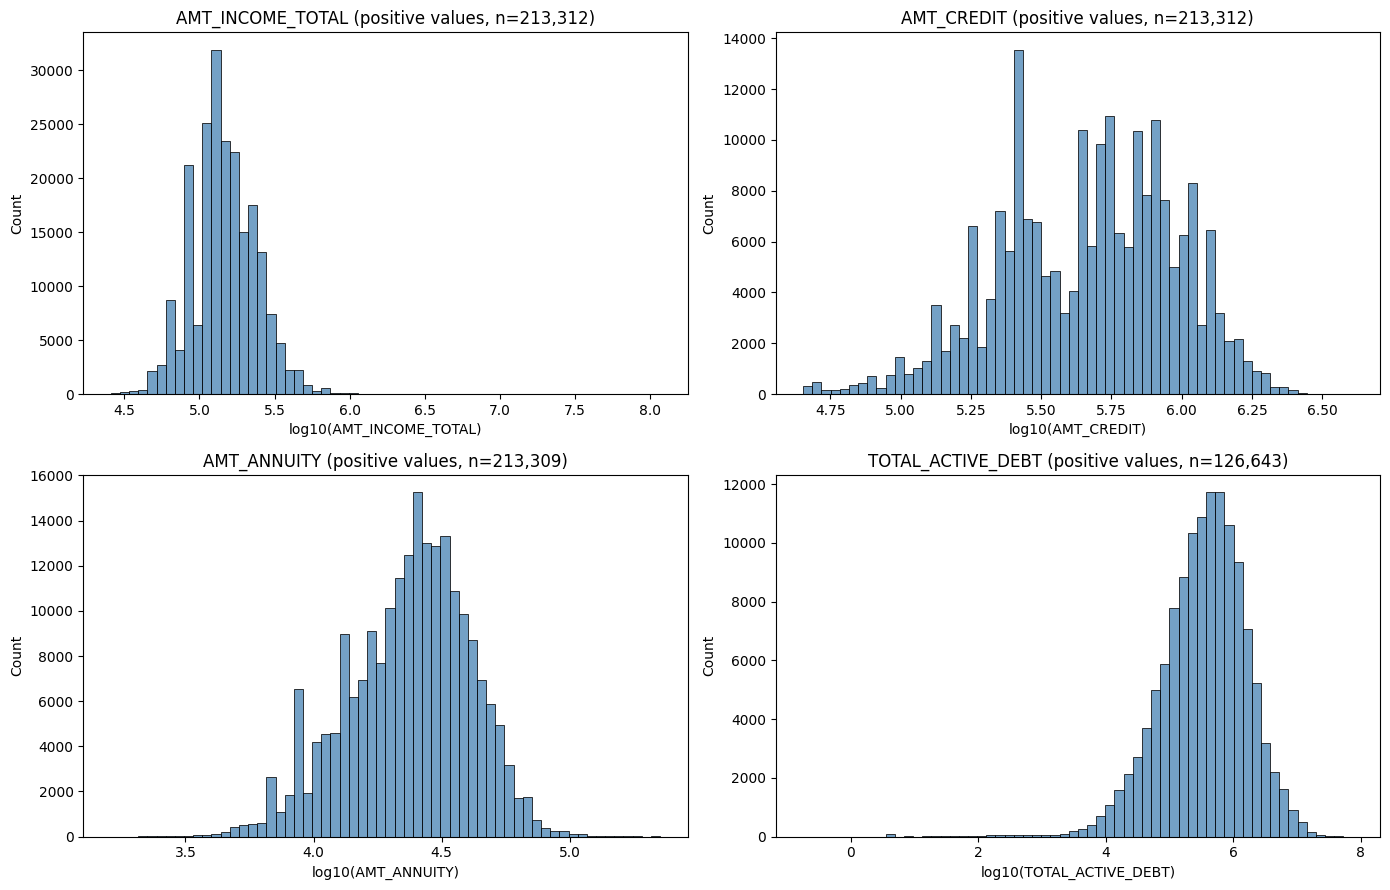

In [13]:
# histograms of key financial characteristics (log scale for the heavily skewed amounts)
plot_vars = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'TOTAL_ACTIVE_DEBT']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for var, axis in zip(plot_vars, axes.flatten()):
    values = merged_df[var].dropna()
    values = values[values > 0]
    sns.histplot(np.log10(values), bins=60, ax=axis, color='steelblue')
    axis.set_xlabel(f'log10({var})')
    axis.set_title(f'{var} (positive values, n={len(values):,})')
plt.tight_layout()
plt.show()

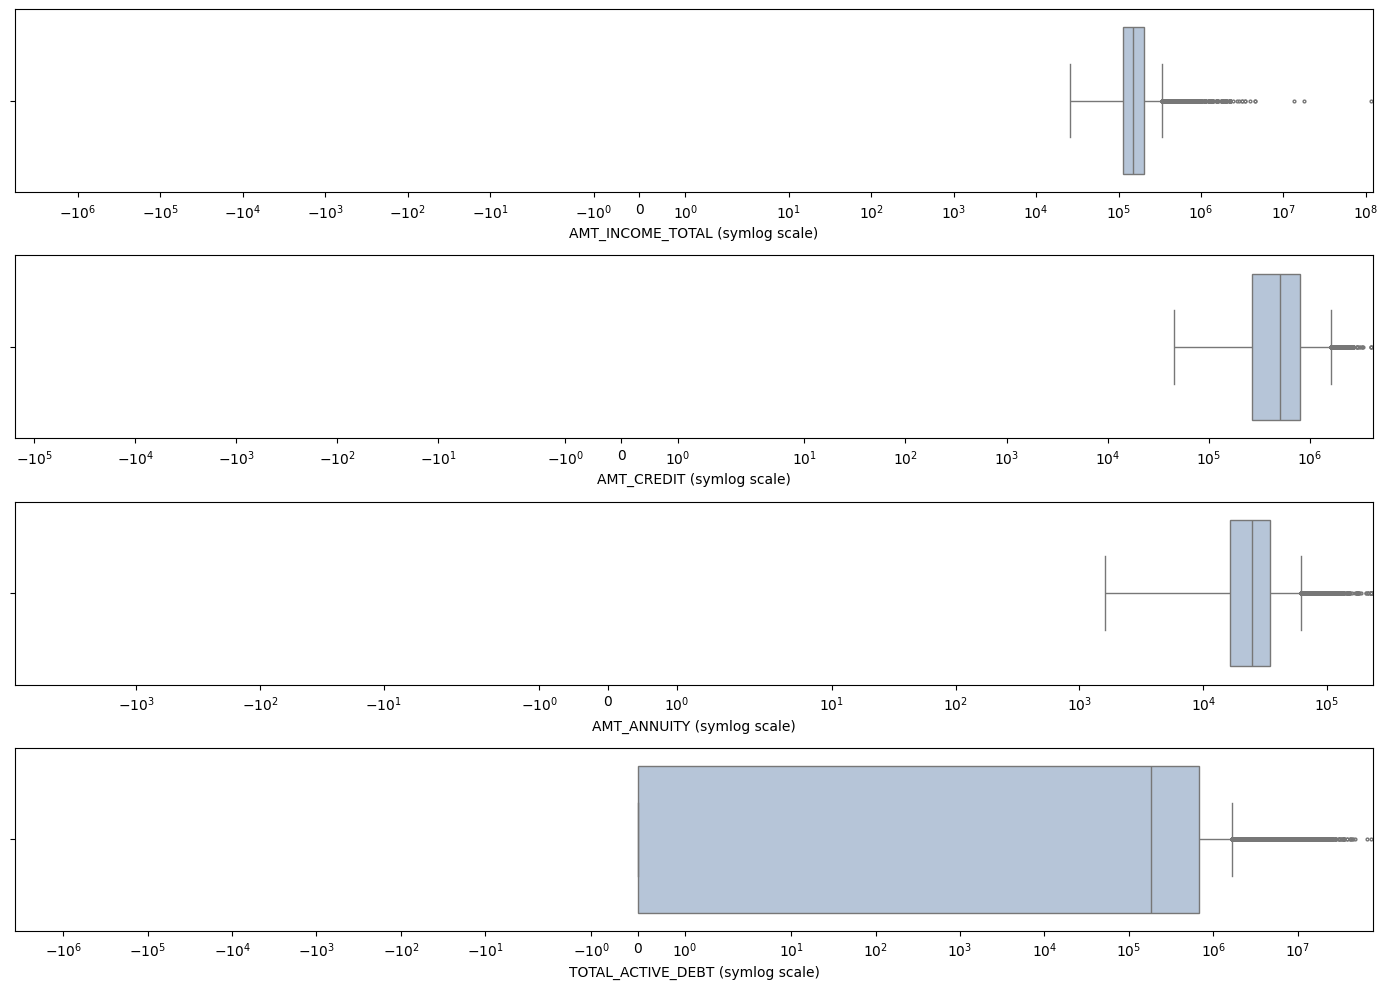

In [14]:
# boxplots to show the spread and extreme values
fig, axes = plt.subplots(len(plot_vars), 1, figsize=(14, 10))
for var, axis in zip(plot_vars, axes):
    sns.boxplot(x=merged_df[var], ax=axis, orient='h', color='lightsteelblue', fliersize=2)
    axis.set_xscale('symlog')
    axis.set_xlabel(f'{var} (symlog scale)')
plt.tight_layout()
plt.show()

Income, credit amount, annuity and bureau debt are all strongly right-skewed with long upper tails (hence the log scales). `TOTAL_ACTIVE_DEBT` also has a large mass at exactly 0, which are applicants whose bureau accounts are all closed.

### D. Outlier and invalid-value identification

Each check counts affected applicants. Nothing is deleted or capped here. "Extreme" values use the rule *above Q3 + 3 × IQR* purely as a flag.

In [15]:
# helper to count extreme upper values (flag only)
def extreme_count(series):
    q1, q3 = series.quantile([0.25, 0.75])
    return (series > q3 + 3 * (q3 - q1)).sum()

numeric_cols = merged_df.select_dtypes('number').columns
days_cols = ['DAYS_BIRTH', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']

diagnostics = pd.DataFrame([
    ['AMT_INCOME_TOTAL', 'Income <= 0', (merged_df['AMT_INCOME_TOTAL'] <= 0).sum()],
    ['AMT_INCOME_TOTAL', 'Extreme income (> Q3 + 3*IQR)', extreme_count(merged_df['AMT_INCOME_TOTAL'])],
    ['AMT_CREDIT', 'Credit amount <= 0', (merged_df['AMT_CREDIT'] <= 0).sum()],
    ['AMT_ANNUITY', 'Annuity < 0', (merged_df['AMT_ANNUITY'] < 0).sum()],
    ['AMT_GOODS_PRICE', 'Goods price missing', merged_df['AMT_GOODS_PRICE'].isnull().sum()],
    ['DAYS_BIRTH', 'Age < 18 or > 100', ((-merged_df['DAYS_BIRTH'] / 365.25 < 18) | (-merged_df['DAYS_BIRTH'] / 365.25 > 100)).sum()],
    ['DAYS_EMPLOYED', 'Special code 365243', (merged_df['DAYS_EMPLOYED'] == 365243).sum()],
    ['DAYS_EMPLOYED', 'Other positive values', ((merged_df['DAYS_EMPLOYED'] > 0) & (merged_df['DAYS_EMPLOYED'] != 365243)).sum()],
    ['DAYS_EMPLOYED', 'Employed longer than age - 14 years',
     ((merged_df['DAYS_EMPLOYED'] <= 0) & (-merged_df['DAYS_EMPLOYED'] > -merged_df['DAYS_BIRTH'] - 14 * 365.25)).sum()],
    ['DAYS_REGISTRATION / ID_PUBLISH / LAST_PHONE_CHANGE', 'Positive (future) day values', (merged_df[days_cols] > 0).sum().sum()],
    ['OWN_CAR_AGE', 'Car age > 50 years', (merged_df['OWN_CAR_AGE'] > 50).sum()],
    ['CNT_FAM_MEMBERS', 'Family members <= 0 or missing', ((merged_df['CNT_FAM_MEMBERS'] <= 0) | merged_df['CNT_FAM_MEMBERS'].isnull()).sum()],
    ['CODE_GENDER', "Unrecognised code 'XNA'", (merged_df['CODE_GENDER'] == 'XNA').sum()],
    ['TOTAL_ACTIVE_DEBT', 'Extreme debt (> Q3 + 3*IQR)', extreme_count(merged_df['TOTAL_ACTIVE_DEBT'].dropna())],
    ['TOTAL_ACTIVE_DEBT', 'Negative debt', (merged_df['TOTAL_ACTIVE_DEBT'] < 0).sum()],
    ['TOTAL_OVERDUE_AMOUNT', 'Negative overdue amount', (merged_df['TOTAL_OVERDUE_AMOUNT'] < 0).sum()],
    ['MAX_REMAINING_DURATION', 'Remaining duration > 30 years', (merged_df['MAX_REMAINING_DURATION'] > 30).sum()],
    ['All numeric columns', 'Infinite values', sum(np.isinf(merged_df[c]).sum() for c in numeric_cols)],
], columns=['Characteristic', 'Check', 'Affected observations'])

diagnostics.style.format({'Affected observations': '{:,.0f}'})

,Characteristic,Check,Affected observations
0,AMT_INCOME_TOTAL,Income <= 0,0
1,AMT_INCOME_TOTAL,Extreme income (> Q3 + 3*IQR),"2,095"
2,AMT_CREDIT,Credit amount <= 0,0
3,AMT_ANNUITY,Annuity < 0,0
4,AMT_GOODS_PRICE,Goods price missing,223
5,DAYS_BIRTH,Age < 18 or > 100,0
6,DAYS_EMPLOYED,Special code 365243,"42,230"
7,DAYS_EMPLOYED,Other positive values,0
8,DAYS_EMPLOYED,Employed longer than age - 14 years,0
9,DAYS_REGISTRATION / ID_PUBLISH / LAST_PHONE_CHANGE,Positive (future) day values,0


In [16]:
# who has the DAYS_EMPLOYED special code?
merged_df.loc[merged_df['DAYS_EMPLOYED'] == 365243, 'NAME_INCOME_TYPE'].value_counts().to_frame('Applicants with 365243')

,Applicants with 365243
NAME_INCOME_TYPE,
Pensioner,42215
Unemployed,15


**Findings**

- No zero/negative income, credit or annuity values, no impossible ages, and no future day values. A handful of applicants are missing `AMT_ANNUITY` (3) or `CNT_FAM_MEMBERS` (2); ratios using them are left missing.
- `DAYS_EMPLOYED = 365243` (about 1,000 years) is a **special code**, not a real tenure. Every affected applicant is a *Pensioner* or *Unemployed*, so it is a "not currently employed" marker. This is the only correction made: the raw column is kept unchanged, and the engineered `EMPLOYMENT_YEARS` treats the code as missing, with a separate flag `FLAG_DAYS_EMPLOYED_SPECIAL` recording it.
- `AMT_GOODS_PRICE` is missing for a small number of applicants (all on revolving loans, where there is no goods price).
- Extreme incomes, bureau debts, long remaining durations, very old cars and four `CODE_GENDER = 'XNA'` records are **flagged only**. They are plausible or uncertain, so they are left for the comprehensive data-preparation step. (`CODE_GENDER` is in any case excluded from modelling on fair-lending grounds.)

## 2.5 Application-Specific Feature Engineering

Each feature below has a clear financial meaning. All ratios use a **safe division** rule: if the numerator or denominator is missing, or the denominator is zero/negative where that is economically invalid, the result is `NaN`. No rows are dropped and no constants are substituted.

**Units check from the data dictionary**

The dictionary defines `AMT_INCOME_TOTAL` as *"Income of the client"* and `AMT_ANNUITY` as *"Loan annuity"*, but **does not state the period** of either. We test the brief's monthly assumption below before using it.

In [17]:
# dictionary definitions of the inputs used
used_inputs = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
               'CNT_FAM_MEMBERS', 'YEARS_BUILD_AVG', 'YEARS_BEGINEXPLUATATION_AVG']
with pd.option_context('display.max_colwidth', 200):
    display(app_dict[app_dict.iloc[:, 0].isin(used_inputs)].set_index(app_dict.columns[0]))

,Description,Special
Row,,
AMT_INCOME_TOTAL,Income of the client,NaN
AMT_CREDIT,Credit amount of the loan,NaN
AMT_ANNUITY,Loan annuity,NaN
AMT_GOODS_PRICE,For consumer loans it is the price of the goods for which the loan is given,NaN
DAYS_BIRTH,Client's age in days at the time of application,time only relative to the application
DAYS_EMPLOYED,How many days before the application the person started current employment,time only relative to the application
CNT_FAM_MEMBERS,How many family members does client have,NaN
YEARS_BEGINEXPLUATATION_AVG,"Normalized information about building where the client lives, What is average (_AVG suffix), modus (_MODE suffix), median (_MEDI suffix) apartment size, common area, living area, age of building, ...",normalized
YEARS_BUILD_AVG,"Normalized information about building where the client lives, What is average (_AVG suffix), modus (_MODE suffix), median (_MEDI suffix) apartment size, common area, living area, age of building, ...",normalized


In [18]:
# safe division: NaN when inputs are missing or the denominator is zero/negative
def safe_divide(numerator, denominator):
    valid = numerator.notnull() & denominator.notnull() & (denominator > 0)
    return (numerator / denominator).where(valid)

new_app_features = []

### 1. Applicant Age

`AGE_YEARS = -DAYS_BIRTH / 365.25`, the applicant's age at application.

In [19]:
merged_df['AGE_YEARS'] = -merged_df['DAYS_BIRTH'] / 365.25
new_app_features.append('AGE_YEARS')
merged_df['AGE_YEARS'].describe()

count   213,312.0000
mean         44.8529
std          11.9128
min          20.5038
25%          35.1896
50%          44.5366
75%          54.7844
max          69.0732
Name: AGE_YEARS, dtype: float64

### 2. Employment Tenure

`EMPLOYMENT_YEARS = -DAYS_EMPLOYED / 365.25`, with the special code 365243 treated as missing (not employed), and a flag recording the special code so that this information is not lost.

In [20]:
# special code -> flag, tenure set to missing for those applicants
special_emp = merged_df['DAYS_EMPLOYED'] == 365243
merged_df['FLAG_DAYS_EMPLOYED_SPECIAL'] = special_emp.astype(int)
merged_df['EMPLOYMENT_YEARS'] = (-merged_df['DAYS_EMPLOYED'] / 365.25).where(~special_emp)
new_app_features += ['FLAG_DAYS_EMPLOYED_SPECIAL', 'EMPLOYMENT_YEARS']

print(f'Special code applicants: {special_emp.sum():,}')
merged_df['EMPLOYMENT_YEARS'].describe()

Special code applicants: 42,230


count   171,082.0000
mean          6.6626
std           6.5433
min           0.0000
25%           2.1355
50%           4.5640
75%           8.8816
max          49.0404
Name: EMPLOYMENT_YEARS, dtype: float64

### Testing the income/annuity period assumption

If income were annual and annuity monthly, `AMT_ANNUITY / (AMT_INCOME_TOTAL / 12)` would be the share of monthly income spent on the instalment.

In [21]:
# test the brief's monthly assumption
monthly_test = safe_divide(merged_df['AMT_ANNUITY'], merged_df['AMT_INCOME_TOTAL'] / 12)
print(f'Median AMT_ANNUITY / (AMT_INCOME_TOTAL / 12): {monthly_test.median():.2f}')
print(f'Share of applicants above 1.0 (instalment > monthly income): {(monthly_test > 1).mean():.1%}')
print(f'Median AMT_CREDIT / AMT_ANNUITY (implied number of instalments): {safe_divide(merged_df["AMT_CREDIT"], merged_df["AMT_ANNUITY"]).median():.1f}')

Median AMT_ANNUITY / (AMT_INCOME_TOTAL / 12): 1.94
Share of applicants above 1.0 (instalment > monthly income): 88.3%
Median AMT_CREDIT / AMT_ANNUITY (implied number of instalments): 20.0


Under the monthly assumption the typical applicant would pay about twice their monthly income in instalments, and most would pay more than 100% of it, which is not plausible for approved loans. The income and annuity periods therefore **cannot be confirmed as annual vs monthly**. The data are more consistent with both being on the **same period basis**.

Decision: income-based ratios are computed on the **same-period basis** (`AMT_ANNUITY / AMT_INCOME_TOTAL`). They are treated as **relative burden indices**, not confirmed monthly debt-service ratios. Multiplying by 12 would not change any applicant's ranking (and so would not change later binning), but would display a misleading percentage.

### 3–6. Affordability and household ratios

| Feature | Formula | Interpretation |
|---|---|---|
| `LOAN_TO_INCOME` | `AMT_CREDIT / AMT_INCOME_TOTAL` | Requested borrowing relative to reported income (income period assumed consistent across applicants). |
| `ANNUITY_TO_INCOME` | `AMT_ANNUITY / AMT_INCOME_TOTAL` | Instalment burden relative to income, **same-period basis** (see test above). |
| `CREDIT_TO_GOODS_RATIO` | `AMT_CREDIT / AMT_GOODS_PRICE` | Financing relative to the price of the goods; above 1 means borrowing more than the goods price (e.g. fees, insurance). |
| `INCOME_PER_FAMILY_MEMBER` | `AMT_INCOME_TOTAL / CNT_FAM_MEMBERS` | Resources per household member, assuming reported income is the applicant's own. |

In [22]:
merged_df['LOAN_TO_INCOME'] = safe_divide(merged_df['AMT_CREDIT'], merged_df['AMT_INCOME_TOTAL'])
merged_df['ANNUITY_TO_INCOME'] = safe_divide(merged_df['AMT_ANNUITY'], merged_df['AMT_INCOME_TOTAL'])
merged_df['CREDIT_TO_GOODS_RATIO'] = safe_divide(merged_df['AMT_CREDIT'], merged_df['AMT_GOODS_PRICE'])
merged_df['INCOME_PER_FAMILY_MEMBER'] = safe_divide(merged_df['AMT_INCOME_TOTAL'], merged_df['CNT_FAM_MEMBERS'])
new_app_features += ['LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'CREDIT_TO_GOODS_RATIO', 'INCOME_PER_FAMILY_MEMBER']

# goods price coverage by contract type
print('AMT_GOODS_PRICE missing by contract type:')
print(merged_df.groupby('NAME_CONTRACT_TYPE')['AMT_GOODS_PRICE'].apply(lambda s: s.isnull().sum()).to_string())

merged_df[['LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'CREDIT_TO_GOODS_RATIO', 'INCOME_PER_FAMILY_MEMBER']].describe().T

AMT_GOODS_PRICE missing by contract type:
NAME_CONTRACT_TYPE
Cash loans           0
Revolving loans    223


,count,mean,std,min,25%,50%,75%,max
LOAN_TO_INCOME,"213,312.0000",3.8703,2.6414,0.0048,2.0000,3.1600,5.0333,84.7368
ANNUITY_TO_INCOME,"213,309.0000",0.1797,0.0939,0.0002,0.1138,0.1618,0.2272,1.8760
CREDIT_TO_GOODS_RATIO,"213,089.0000",1.1255,0.1245,0.1500,1.0000,1.1188,1.1980,6.0000
INCOME_PER_FAMILY_MEMBER,"213,310.0000","92,998.4444","110,823.2782","4,875.0000","48,000.0000","75,000.0000","112,500.0000","39,000,000.0000"


`AMT_GOODS_PRICE` is available for all cash loans and missing only for some revolving loans, so `CREDIT_TO_GOODS_RATIO` is well populated. The missing values stay missing.

### 7. Employment-to-Age Ratio (exploratory)

`EMPLOYMENT_AGE_RATIO = EMPLOYMENT_YEARS / AGE_YEARS`, the share of life spent in the current job. It is missing for the special-code applicants (not employed). It is exploratory: a young applicant with 3 years in their job and an older applicant with 12 years can have the same ratio.

In [23]:
merged_df['EMPLOYMENT_AGE_RATIO'] = safe_divide(merged_df['EMPLOYMENT_YEARS'], merged_df['AGE_YEARS'])
new_app_features.append('EMPLOYMENT_AGE_RATIO')
merged_df['EMPLOYMENT_AGE_RATIO'].describe()

count   171,082.0000
mean          0.1575
std           0.1352
min           0.0000
25%           0.0559
50%           0.1180
75%           0.2198
max           0.7288
Name: EMPLOYMENT_AGE_RATIO, dtype: float64

### Additional application feature: implied repayment term

`CREDIT_TO_ANNUITY_RATIO = AMT_CREDIT / AMT_ANNUITY` is the number of instalments implied by the loan amount and its annuity, i.e. how long the applicant is committing to repay. Longer terms can mean lower instalments but longer exposure. Like the income ratios, it is computed on whatever period basis the annuity uses.

In [24]:
merged_df['CREDIT_TO_ANNUITY_RATIO'] = safe_divide(merged_df['AMT_CREDIT'], merged_df['AMT_ANNUITY'])
new_app_features.append('CREDIT_TO_ANNUITY_RATIO')
merged_df['CREDIT_TO_ANNUITY_RATIO'].describe()

count   213,309.0000
mean         21.2251
std           7.5718
min           8.0367
25%          15.5456
50%          20.0000
75%          26.2540
max          45.3051
Name: CREDIT_TO_ANNUITY_RATIO, dtype: float64

### 8. Property characteristics

We reviewed the dictionary's housing/property variables before creating anything:

In [25]:
# review the building / property variables
property_cols = ['YEARS_BUILD_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'TOTALAREA_MODE', 'EMERGENCYSTATE_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE']
property_review = pd.DataFrame({
    'Missing %': merged_df[property_cols].isnull().mean() * 100,
    'Type': merged_df[property_cols].dtypes.astype(str),
    'Min / categories': [f"{merged_df[c].min():.3f}" if merged_df[c].dtype != 'O' else ', '.join(merged_df[c].dropna().unique()[:4])
                         for c in property_cols],
    'Max': [f"{merged_df[c].max():.3f}" if merged_df[c].dtype != 'O' else '' for c in property_cols],
})
property_review

,Missing %,Type,Min / categories,Max
YEARS_BUILD_AVG,65.9930,float64,0.000,1.000
YEARS_BEGINEXPLUATATION_AVG,48.0714,float64,0.000,1.000
TOTALAREA_MODE,47.5791,float64,0.000,1.000
EMERGENCYSTATE_MODE,46.7165,object,"No, Yes",
HOUSETYPE_MODE,49.4726,object,"block of flats, terraced house, specific housing",
WALLSMATERIAL_MODE,50.0586,object,"Stone, brick, Panel, Mixed, Wooden",


**Decision: no property features are engineered.**

- The dictionary describes these as *"Normalized information about building where the client lives"*. `YEARS_BUILD_AVG` is scaled to 0–1, so the actual construction year (and therefore **property age**) cannot be recovered.
- They describe the building where the client **lives**, which is not necessarily the property they **own** (Step 0 deliberately kept owners living elsewhere).
- They are 48–66% missing.
- Condition indicators such as `EMERGENCYSTATE_MODE` and `WALLSMATERIAL_MODE` already exist as categorical characteristics and can be screened directly with WOE/IV later.

Combining normalised metrics measured on different scales, or inventing a property value, would not be supported by the data.

## 2.6 Cross-Dataset Feature Engineering

These features combine application and bureau information and cannot be built from either source alone. First, check which bureau inputs actually exist in the flattened file.

In [26]:
# check the real bureau column names before using them
required_inputs = {
    'BUREAU_DEBT_TO_INCOME': ['TOTAL_ACTIVE_DEBT', 'AMT_INCOME_TOTAL'],
    'TOTAL_EXPOSURE_TO_INCOME': ['TOTAL_ACTIVE_DEBT', 'AMT_CREDIT', 'AMT_INCOME_TOTAL'],
    'BUREAU_ANNUITY_TO_INCOME': ['TOTAL_ACTIVE_ANNUITY', 'AMT_INCOME_TOTAL'],
    'COMBINED_ANNUITY_TO_INCOME': ['TOTAL_ACTIVE_ANNUITY', 'AMT_ANNUITY', 'AMT_INCOME_TOTAL'],
    'AVG_DEBT_PER_ACTIVE_LOAN': ['TOTAL_ACTIVE_DEBT', 'ACTIVE_LOAN_COUNT'],
    'CREDIT_HISTORY_AGE_RATIO': ['OLDEST_CREDIT_AGE', 'AGE_YEARS'],
    'ACTIVE_LOANS_PER_INCOME': ['ACTIVE_LOAN_COUNT', 'AMT_INCOME_TOTAL'],
    'EXISTING_DEBT_SHARE_OF_EXPOSURE': ['TOTAL_ACTIVE_DEBT', 'AMT_CREDIT'],
}

print('Flattened bureau columns:', bureau_cols, '\n')
availability = pd.DataFrame({
    'Required inputs': [', '.join(v) for v in required_inputs.values()],
    'Missing inputs': [', '.join(c for c in v if c not in merged_df.columns) or '-' for v in required_inputs.values()],
}, index=list(required_inputs))
availability['Can be created'] = availability['Missing inputs'] == '-'
availability.index.name = 'Feature'
availability

Flattened bureau columns: ['BUREAU_LOAN_COUNT', 'ACTIVE_LOAN_COUNT', 'ADVERSE_STATUS_COUNT', 'ACTIVE_LOAN_RATIO', 'CREDIT_TYPE_DIVERSITY', 'TOTAL_ACTIVE_DEBT', 'DEBT_TO_CREDIT_RATIO', 'TOTAL_REVOLVING_LIMIT', 'MAX_DAYS_OVERDUE', 'OVERDUE_LOAN_COUNT', 'TOTAL_OVERDUE_AMOUNT', 'MAX_HIST_OVERDUE', 'TOTAL_PROLONGATIONS', 'OLDEST_CREDIT_AGE', 'MOST_RECENT_CREDIT_AGE', 'MAX_REMAINING_DURATION', 'LAST_CREDIT_END_AGE', 'LATEST_BUREAU_UPDATE_AGE', 'ACTIVE_CONSUMER_CREDIT_COUNT', 'ACTIVE_CREDIT_CARD_COUNT', 'MORTGAGE_COUNT', 'CAR_LOAN_COUNT', 'MICROLOAN_COUNT'] 



,Required inputs,Missing inputs,Can be created
Feature,,,
BUREAU_DEBT_TO_INCOME,"TOTAL_ACTIVE_DEBT, AMT_INCOME_TOTAL",-,True
TOTAL_EXPOSURE_TO_INCOME,"TOTAL_ACTIVE_DEBT, AMT_CREDIT, AMT_INCOME_TOTAL",-,True
BUREAU_ANNUITY_TO_INCOME,"TOTAL_ACTIVE_ANNUITY, AMT_INCOME_TOTAL",TOTAL_ACTIVE_ANNUITY,False
COMBINED_ANNUITY_TO_INCOME,"TOTAL_ACTIVE_ANNUITY, AMT_ANNUITY, AMT_INCOME_...",TOTAL_ACTIVE_ANNUITY,False
AVG_DEBT_PER_ACTIVE_LOAN,"TOTAL_ACTIVE_DEBT, ACTIVE_LOAN_COUNT",-,True
CREDIT_HISTORY_AGE_RATIO,"OLDEST_CREDIT_AGE, AGE_YEARS",-,True
ACTIVE_LOANS_PER_INCOME,"ACTIVE_LOAN_COUNT, AMT_INCOME_TOTAL",-,True
EXISTING_DEBT_SHARE_OF_EXPOSURE,"TOTAL_ACTIVE_DEBT, AMT_CREDIT",-,True


`TOTAL_ACTIVE_ANNUITY` is **not** in the flattened bureau file. Step 1 dropped it because bureau annuities were unreported for about 59% of applicants. Therefore **`BUREAU_ANNUITY_TO_INCOME` and `COMBINED_ANNUITY_TO_INCOME` cannot be created**. We do not substitute another variable or reload the full feature file, because a repayment-burden measure built on mostly missing annuities would be misleading.

**Double-counting check.** `TOTAL_EXPOSURE_TO_INCOME` adds existing bureau debt to the requested loan. If the bureau already contained the current loan, it would be counted twice. The bureau records credits from other institutions reported *before* the application. A credit opened on the application day would have `MOST_RECENT_CREDIT_AGE = 0`:

In [27]:
# applicants with a bureau credit opened on the application day
same_day = (merged_df['MOST_RECENT_CREDIT_AGE'] == 0).sum()
print(f'Applicants with a bureau credit opened on the application day: {same_day} ({same_day / merged_df["HAS_BUREAU_HISTORY"].sum():.4%} of matched)')

Applicants with a bureau credit opened on the application day: 4 (0.0022% of matched)


Only a handful of applicants have any bureau credit opened on the application day, so double counting of the current loan is negligible.

**Features created**

| Feature | Formula | Interpretation |
|---|---|---|
| `BUREAU_DEBT_TO_INCOME` | `TOTAL_ACTIVE_DEBT / AMT_INCOME_TOTAL` | Existing outstanding debt relative to income. Two borrowers with the same debt can have very different capacity. |
| `TOTAL_EXPOSURE_TO_INCOME` | `(TOTAL_ACTIVE_DEBT + AMT_CREDIT) / AMT_INCOME_TOTAL` | Existing debt plus the requested loan relative to income. A **balance-to-income** measure, not a repayment ratio. |
| `AVG_DEBT_PER_ACTIVE_LOAN` | `TOTAL_ACTIVE_DEBT / ACTIVE_LOAN_COUNT` | Typical size of each current obligation. Missing when there are no active loans. |
| `CREDIT_HISTORY_AGE_RATIO` | `OLDEST_CREDIT_AGE / AGE_YEARS` | Observable credit history relative to age. |
| `ACTIVE_LOANS_PER_INCOME` | `ACTIVE_LOAN_COUNT / (AMT_INCOME_TOTAL / 100,000)` | Number of current obligations per 100,000 of income (exploratory). |
| `EXISTING_DEBT_SHARE_OF_EXPOSURE` | `TOTAL_ACTIVE_DEBT / (TOTAL_ACTIVE_DEBT + AMT_CREDIT)` | Share of total post-loan exposure that is existing debt: how much the new loan adds to an already-indebted applicant (additional feature). |

All are missing for applicants without bureau history and whenever a bureau input is missing. They are never set to zero.

In [28]:
# cross-dataset features (only those whose inputs exist)
new_cross_features = []
total_exposure = merged_df['TOTAL_ACTIVE_DEBT'] + merged_df['AMT_CREDIT']

if availability.loc['BUREAU_DEBT_TO_INCOME', 'Can be created']:
    merged_df['BUREAU_DEBT_TO_INCOME'] = safe_divide(merged_df['TOTAL_ACTIVE_DEBT'], merged_df['AMT_INCOME_TOTAL'])
    new_cross_features.append('BUREAU_DEBT_TO_INCOME')

if availability.loc['TOTAL_EXPOSURE_TO_INCOME', 'Can be created']:
    merged_df['TOTAL_EXPOSURE_TO_INCOME'] = safe_divide(total_exposure, merged_df['AMT_INCOME_TOTAL'])
    new_cross_features.append('TOTAL_EXPOSURE_TO_INCOME')

if availability.loc['AVG_DEBT_PER_ACTIVE_LOAN', 'Can be created']:
    merged_df['AVG_DEBT_PER_ACTIVE_LOAN'] = safe_divide(merged_df['TOTAL_ACTIVE_DEBT'], merged_df['ACTIVE_LOAN_COUNT'])
    new_cross_features.append('AVG_DEBT_PER_ACTIVE_LOAN')

if availability.loc['CREDIT_HISTORY_AGE_RATIO', 'Can be created']:
    merged_df['CREDIT_HISTORY_AGE_RATIO'] = safe_divide(merged_df['OLDEST_CREDIT_AGE'], merged_df['AGE_YEARS'])
    new_cross_features.append('CREDIT_HISTORY_AGE_RATIO')

if availability.loc['ACTIVE_LOANS_PER_INCOME', 'Can be created']:
    merged_df['ACTIVE_LOANS_PER_INCOME'] = safe_divide(merged_df['ACTIVE_LOAN_COUNT'], merged_df['AMT_INCOME_TOTAL'] / 100000)
    new_cross_features.append('ACTIVE_LOANS_PER_INCOME')

if availability.loc['EXISTING_DEBT_SHARE_OF_EXPOSURE', 'Can be created']:
    merged_df['EXISTING_DEBT_SHARE_OF_EXPOSURE'] = safe_divide(merged_df['TOTAL_ACTIVE_DEBT'], total_exposure)
    new_cross_features.append('EXISTING_DEBT_SHARE_OF_EXPOSURE')

not_created = availability.index[~availability['Can be created']].tolist()
print('Created:', new_cross_features)
print('Not created (missing inputs):', not_created)

merged_df[new_cross_features].describe().T

Created: ['BUREAU_DEBT_TO_INCOME', 'TOTAL_EXPOSURE_TO_INCOME', 'AVG_DEBT_PER_ACTIVE_LOAN', 'CREDIT_HISTORY_AGE_RATIO', 'ACTIVE_LOANS_PER_INCOME', 'EXISTING_DEBT_SHARE_OF_EXPOSURE']
Not created (missing inputs): ['BUREAU_ANNUITY_TO_INCOME', 'COMBINED_ANNUITY_TO_INCOME']


,count,mean,std,min,25%,50%,75%,max
BUREAU_DEBT_TO_INCOME,"174,539.0000",3.6894,7.5371,0.0000,0.0000,1.2618,4.3407,388.0000
TOTAL_EXPOSURE_TO_INCOME,"174,539.0000",7.5349,7.9757,0.0091,3.2728,5.5786,9.0912,394.0000
AVG_DEBT_PER_ACTIVE_LOAN,"142,239.0000","353,436.4444","866,554.7686",0.0000,"42,526.6650","134,043.7500","329,646.1837","43,650,000.0000"
CREDIT_HISTORY_AGE_RATIO,"181,841.0000",0.1116,0.0583,0.0000,0.0663,0.1129,0.1502,0.3066
ACTIVE_LOANS_PER_INCOME,"181,841.0000",1.4183,1.4382,0.0000,0.4938,1.1111,1.9048,26.6667
EXISTING_DEBT_SHARE_OF_EXPOSURE,"174,539.0000",0.3278,0.3054,0.0000,0.0000,0.2722,0.5863,0.9954


In [29]:
# credit history ratio: check the bureau observation window
print(f"Maximum OLDEST_CREDIT_AGE in bureau data: {merged_df['OLDEST_CREDIT_AGE'].max():.2f} years")
print(f"Applicants whose oldest credit would have started before age 18: "
      f"{((merged_df['AGE_YEARS'] - merged_df['OLDEST_CREDIT_AGE']) < 18).sum()}")

Maximum OLDEST_CREDIT_AGE in bureau data: 8.00 years
Applicants whose oldest credit would have started before age 18: 13


`CREDIT_HISTORY_AGE_RATIO` must be read with care: the bureau only shows credits opened within about the **last 8 years**, so `OLDEST_CREDIT_AGE` is capped there. For older applicants the ratio understates true history; it is most informative for younger applicants. A few applicants appear to have started credit before 18, which is likely a data-quality issue to review later.

## 2.7 Validate Newly Engineered Characteristics

In [30]:
# quality review for every new characteristic
formulas = {
    'AGE_YEARS': '-DAYS_BIRTH / 365.25',
    'FLAG_DAYS_EMPLOYED_SPECIAL': 'DAYS_EMPLOYED == 365243',
    'EMPLOYMENT_YEARS': '-DAYS_EMPLOYED / 365.25 (special code -> NaN)',
    'LOAN_TO_INCOME': 'AMT_CREDIT / AMT_INCOME_TOTAL',
    'ANNUITY_TO_INCOME': 'AMT_ANNUITY / AMT_INCOME_TOTAL (same period)',
    'CREDIT_TO_GOODS_RATIO': 'AMT_CREDIT / AMT_GOODS_PRICE',
    'INCOME_PER_FAMILY_MEMBER': 'AMT_INCOME_TOTAL / CNT_FAM_MEMBERS',
    'EMPLOYMENT_AGE_RATIO': 'EMPLOYMENT_YEARS / AGE_YEARS',
    'CREDIT_TO_ANNUITY_RATIO': 'AMT_CREDIT / AMT_ANNUITY',
    'BUREAU_DEBT_TO_INCOME': 'TOTAL_ACTIVE_DEBT / AMT_INCOME_TOTAL',
    'TOTAL_EXPOSURE_TO_INCOME': '(TOTAL_ACTIVE_DEBT + AMT_CREDIT) / AMT_INCOME_TOTAL',
    'AVG_DEBT_PER_ACTIVE_LOAN': 'TOTAL_ACTIVE_DEBT / ACTIVE_LOAN_COUNT',
    'CREDIT_HISTORY_AGE_RATIO': 'OLDEST_CREDIT_AGE / AGE_YEARS',
    'ACTIVE_LOANS_PER_INCOME': 'ACTIVE_LOAN_COUNT / (AMT_INCOME_TOTAL / 100,000)',
    'EXISTING_DEBT_SHARE_OF_EXPOSURE': 'TOTAL_ACTIVE_DEBT / (TOTAL_ACTIVE_DEBT + AMT_CREDIT)',
}
new_features = new_app_features + new_cross_features

validation = pd.DataFrame({
    'Formula / source': [formulas[c] for c in new_features],
    'Non-missing count': [merged_df[c].notnull().sum() for c in new_features],
    'Missing %': [merged_df[c].isnull().mean() * 100 for c in new_features],
    'Minimum': [merged_df[c].min() for c in new_features],
    'Median': [merged_df[c].median() for c in new_features],
    'Maximum': [merged_df[c].max() for c in new_features],
    '99th percentile': [merged_df[c].quantile(0.99) for c in new_features],
    'Negative count': [(merged_df[c] < 0).sum() for c in new_features],
    'Infinite count': [np.isinf(merged_df[c]).sum() for c in new_features],
    'Distinct values': [merged_df[c].nunique() for c in new_features],
}, index=new_features)
validation.index.name = 'Characteristic'

with pd.option_context('display.max_colwidth', None):
    display(validation.style.format({'Non-missing count': '{:,.0f}', 'Missing %': '{:.2f}', 'Minimum': '{:,.3f}', 'Median': '{:,.3f}',
                                     'Maximum': '{:,.3f}', '99th percentile': '{:,.3f}', 'Negative count': '{:,.0f}',
                                     'Infinite count': '{:,.0f}', 'Distinct values': '{:,.0f}'}))

,Formula / source,Non-missing count,Missing %,Minimum,Median,Maximum,99th percentile,Negative count,Infinite count,Distinct values
Characteristic,,,,,,,,,,
AGE_YEARS,-DAYS_BIRTH / 365.25,"213,312",0.00,20.504,44.537,69.073,67.039,0,0,"17,392"
FLAG_DAYS_EMPLOYED_SPECIAL,DAYS_EMPLOYED == 365243,"213,312",0.00,0.000,0.000,1.000,1.000,0,0,2
EMPLOYMENT_YEARS,-DAYS_EMPLOYED / 365.25 (special code -> NaN),"171,082",19.80,0.000,4.564,49.040,31.485,0,0,"11,843"
LOAN_TO_INCOME,AMT_CREDIT / AMT_INCOME_TOTAL,"213,312",0.00,0.005,3.160,84.737,12.729,0,0,"39,925"
ANNUITY_TO_INCOME,AMT_ANNUITY / AMT_INCOME_TOTAL (same period),"213,309",0.00,0.000,0.162,1.876,0.478,0,0,"70,672"
CREDIT_TO_GOODS_RATIO,AMT_CREDIT / AMT_GOODS_PRICE,"213,089",0.10,0.150,1.119,6.000,1.475,0,0,"2,761"
INCOME_PER_FAMILY_MEMBER,AMT_INCOME_TOTAL / CNT_FAM_MEMBERS,"213,310",0.00,"4,875.000","75,000.000","39,000,000.000","337,500.000",0,0,"2,072"
EMPLOYMENT_AGE_RATIO,EMPLOYMENT_YEARS / AGE_YEARS,"171,082",19.80,0.000,0.118,0.729,0.595,0,0,"170,044"
CREDIT_TO_ANNUITY_RATIO,AMT_CREDIT / AMT_ANNUITY,"213,309",0.00,8.037,20.000,45.305,37.244,0,0,"32,664"


In [31]:
# further checks
print('Exact duplicate engineered columns:', merged_df[new_features].T.duplicated().sum())
print('Engineered columns duplicating an existing column:',
      [c for c in new_features if any(merged_df[c].equals(merged_df[o]) for o in app_cols + bureau_cols)])

# missing values propagated from inputs (bureau-based features vs no bureau history)
print('\nCross features missing for applicants WITHOUT bureau history (should be 100%):')
print((merged_df.loc[merged_df['HAS_BUREAU_HISTORY'] == 0, new_cross_features].isnull().mean() * 100).round(2).to_string())
print('\nCross features missing for applicants WITH bureau history:')
print((merged_df.loc[merged_df['HAS_BUREAU_HISTORY'] == 1, new_cross_features].isnull().mean() * 100).round(2).to_string())

# very little variation
print('\nShare of the most common value per new feature (> 95% would be near-constant):')
print((merged_df[new_features].apply(lambda s: s.value_counts(normalize=True).iloc[0]) * 100).round(2).sort_values(ascending=False).head(5).to_string())

Exact duplicate engineered columns: 0


Engineered columns duplicating an existing column: []

Cross features missing for applicants WITHOUT bureau history (should be 100%):
BUREAU_DEBT_TO_INCOME             100.0000
TOTAL_EXPOSURE_TO_INCOME          100.0000
AVG_DEBT_PER_ACTIVE_LOAN          100.0000
CREDIT_HISTORY_AGE_RATIO          100.0000
ACTIVE_LOANS_PER_INCOME           100.0000
EXISTING_DEBT_SHARE_OF_EXPOSURE   100.0000

Cross features missing for applicants WITH bureau history:
BUREAU_DEBT_TO_INCOME              4.0200
TOTAL_EXPOSURE_TO_INCOME           4.0200
AVG_DEBT_PER_ACTIVE_LOAN          21.7800
CREDIT_HISTORY_AGE_RATIO           0.0000
ACTIVE_LOANS_PER_INCOME            0.0000
EXISTING_DEBT_SHARE_OF_EXPOSURE    4.0200

Share of the most common value per new feature (> 95% would be near-constant):


FLAG_DAYS_EMPLOYED_SPECIAL        80.2000
CREDIT_TO_GOODS_RATIO             34.0900
BUREAU_DEBT_TO_INCOME             27.4400
EXISTING_DEBT_SHARE_OF_EXPOSURE   27.4400
ACTIVE_LOANS_PER_INCOME           17.7600


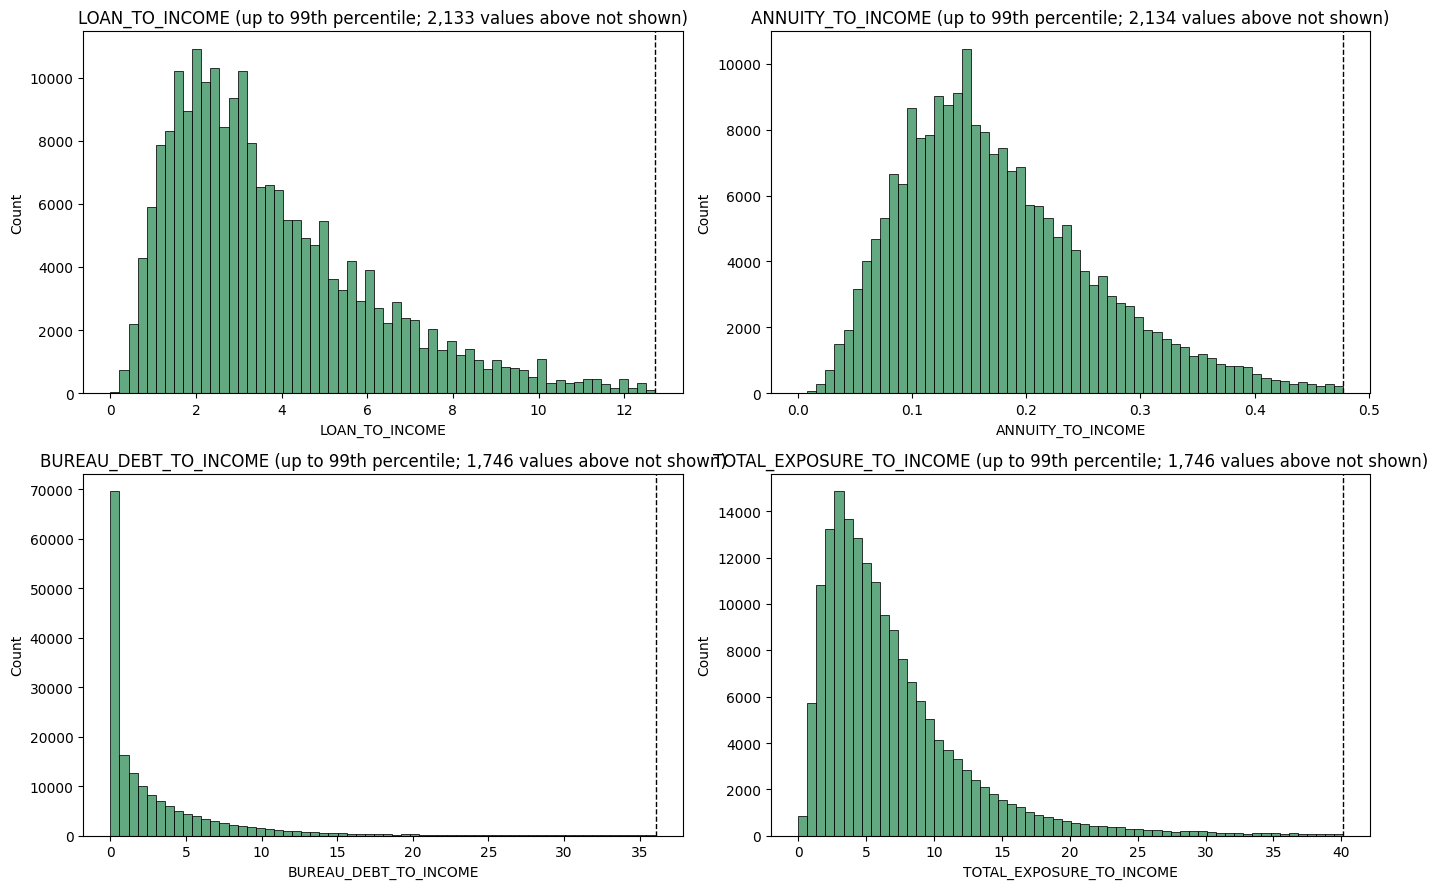

In [32]:
# distributions of selected new ratios (99th percentile shown as a dashed line)
ratio_plots = ['LOAN_TO_INCOME', 'ANNUITY_TO_INCOME', 'BUREAU_DEBT_TO_INCOME', 'TOTAL_EXPOSURE_TO_INCOME']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for var, axis in zip(ratio_plots, axes.flatten()):
    values = merged_df[var].dropna()
    p99 = values.quantile(0.99)
    sns.histplot(values[values <= p99], bins=60, ax=axis, color='seagreen')
    axis.axvline(p99, color='black', linestyle='--', linewidth=1)
    axis.set_title(f'{var} (up to 99th percentile; {(values > p99).sum():,} values above not shown)')
plt.tight_layout()
plt.show()

**Validation findings**

- **No infinite values and no negative values** in any new characteristic. Safe division converted zero denominators to `NaN`.
- **Large ratios:** the income-based ratios (`LOAN_TO_INCOME`, `BUREAU_DEBT_TO_INCOME`, `TOTAL_EXPOSURE_TO_INCOME`) have maxima far above their 99th percentiles, driven by very large bureau debts or very low incomes. They are **kept unchanged**; coarse classing will group the tail.
- **Missing values propagate as intended:** cross-dataset features are 100% missing for applicants without bureau history, and partly missing for matched applicants where the bureau input is missing or not applicable (e.g. `AVG_DEBT_PER_ACTIVE_LOAN` when there are no active loans). `EMPLOYMENT_YEARS` and `EMPLOYMENT_AGE_RATIO` are missing exactly for the special-code applicants.
- **Little variation:** `FLAG_DAYS_EMPLOYED_SPECIAL` is binary by design; no continuous feature is near-constant.
- **No exact duplicates** of each other or of existing columns. Some new features will correlate with their inputs (e.g. `TOTAL_EXPOSURE_TO_INCOME` with `LOAN_TO_INCOME`). That redundancy is assessed in the next stage, not here.
- **Units:** income-based ratios are on a same-period basis because the income/annuity periods are not stated in the dictionary; they should be presented as relative indices.

## 2.8 Feature Engineering Documentation

The feature dictionary is generated from the columns actually present, so it only lists features that were created. The imported Step 1 bureau features are listed separately.

In [33]:
# documentation for each newly created characteristic
feature_docs = {
    'AGE_YEARS': ('Application', 'Age at application in years.', 'Complete; all applicants are 18+.'),
    'FLAG_DAYS_EMPLOYED_SPECIAL': ('Application', 'Not currently employed (pensioner/unemployed special code).', 'Records the 365243 code so it is not lost when tenure is set to missing.'),
    'EMPLOYMENT_YEARS': ('Application', 'Years in current employment; job stability.', 'Missing for special-code applicants (not employed).'),
    'LOAN_TO_INCOME': ('Application', 'Size of requested loan relative to income.', 'Income period not stated in dictionary; relative measure. Long upper tail.'),
    'ANNUITY_TO_INCOME': ('Application', 'Instalment burden relative to income.', 'Same-period basis; monthly assumption failed plausibility test, so not a confirmed monthly DSR.'),
    'CREDIT_TO_GOODS_RATIO': ('Application', 'Financing relative to goods price; > 1 borrows more than price.', 'Missing where AMT_GOODS_PRICE missing (some revolving loans).'),
    'INCOME_PER_FAMILY_MEMBER': ('Application', 'Household resources per member.', 'Assumes reported income is the applicant\'s own, not household income.'),
    'EMPLOYMENT_AGE_RATIO': ('Application', 'Share of life spent in current job (exploratory).', 'Missing for special-code applicants; different ages can share a ratio.'),
    'CREDIT_TO_ANNUITY_RATIO': ('Application', 'Implied number of instalments (repayment term).', 'Same period basis as annuity.'),
    'BUREAU_DEBT_TO_INCOME': ('Cross-dataset', 'Existing outstanding debt relative to income.', 'Missing without bureau history or when debt unreported; currency-1 debt only.'),
    'TOTAL_EXPOSURE_TO_INCOME': ('Cross-dataset', 'Existing debt + requested loan relative to income (balance, not repayment).', 'Double counting negligible; missing without bureau history.'),
    'AVG_DEBT_PER_ACTIVE_LOAN': ('Cross-dataset', 'Average outstanding balance per active account.', 'Missing when no active loans; debt is currency 1 while count covers all currencies.'),
    'CREDIT_HISTORY_AGE_RATIO': ('Cross-dataset', 'Observable credit history relative to age.', 'Bureau window capped at about 8 years; understates history for older applicants.'),
    'ACTIVE_LOANS_PER_INCOME': ('Cross-dataset', 'Active obligations per 100,000 income (exploratory).', 'Missing without bureau history.'),
    'EXISTING_DEBT_SHARE_OF_EXPOSURE': ('Cross-dataset', 'Share of post-loan exposure that is existing debt.', 'Bounded 0-1; missing without bureau history or when debt unreported.'),
}

feature_dictionary = pd.DataFrame({
    'Category': [feature_docs[c][0] + '-engineered (new)' for c in new_features],
    'Source': ['Application Data' if feature_docs[c][0] == 'Application' else 'Application + Bureau Data' for c in new_features],
    'Formula / method': [formulas[c] for c in new_features],
    'Business interpretation': [feature_docs[c][1] for c in new_features],
    'Data-quality considerations': [feature_docs[c][2] for c in new_features],
}, index=new_features)
feature_dictionary.index.name = 'New characteristic'

# every documented feature must exist in the data
assert all(c in merged_df.columns for c in feature_dictionary.index)

with pd.option_context('display.max_colwidth', None):
    display(feature_dictionary)

,Category,Source,Formula / method,Business interpretation,Data-quality considerations
New characteristic,,,,,
AGE_YEARS,Application-engineered (new),Application Data,-DAYS_BIRTH / 365.25,Age at application in years.,Complete; all applicants are 18+.
FLAG_DAYS_EMPLOYED_SPECIAL,Application-engineered (new),Application Data,DAYS_EMPLOYED == 365243,Not currently employed (pensioner/unemployed special code).,Records the 365243 code so it is not lost when tenure is set to missing.
EMPLOYMENT_YEARS,Application-engineered (new),Application Data,-DAYS_EMPLOYED / 365.25 (special code -> NaN),Years in current employment; job stability.,Missing for special-code applicants (not employed).
LOAN_TO_INCOME,Application-engineered (new),Application Data,AMT_CREDIT / AMT_INCOME_TOTAL,Size of requested loan relative to income.,Income period not stated in dictionary; relative measure. Long upper tail.
ANNUITY_TO_INCOME,Application-engineered (new),Application Data,AMT_ANNUITY / AMT_INCOME_TOTAL (same period),Instalment burden relative to income.,"Same-period basis; monthly assumption failed plausibility test, so not a confirmed monthly DSR."
CREDIT_TO_GOODS_RATIO,Application-engineered (new),Application Data,AMT_CREDIT / AMT_GOODS_PRICE,Financing relative to goods price; > 1 borrows more than price.,Missing where AMT_GOODS_PRICE missing (some revolving loans).
INCOME_PER_FAMILY_MEMBER,Application-engineered (new),Application Data,AMT_INCOME_TOTAL / CNT_FAM_MEMBERS,Household resources per member.,"Assumes reported income is the applicant's own, not household income."
EMPLOYMENT_AGE_RATIO,Application-engineered (new),Application Data,EMPLOYMENT_YEARS / AGE_YEARS,Share of life spent in current job (exploratory).,Missing for special-code applicants; different ages can share a ratio.
CREDIT_TO_ANNUITY_RATIO,Application-engineered (new),Application Data,AMT_CREDIT / AMT_ANNUITY,Implied number of instalments (repayment term).,Same period basis as annuity.


In [34]:
# bureau characteristics imported from Step 1 (not new in this notebook)
imported_bureau = pd.DataFrame({
    'Category': 'Bureau-derived (imported from Step 1)',
    'Missing %': merged_df[bureau_cols].isnull().mean() * 100,
}, index=bureau_cols)
imported_bureau.index.name = 'Imported characteristic'

print('Features NOT created because inputs were missing:', not_created)
imported_bureau.style.format({'Missing %': '{:.2f}'})

Features NOT created because inputs were missing: ['BUREAU_ANNUITY_TO_INCOME', 'COMBINED_ANNUITY_TO_INCOME']


,Category,Missing %
Imported characteristic,,
BUREAU_LOAN_COUNT,Bureau-derived (imported from Step 1),14.75
ACTIVE_LOAN_COUNT,Bureau-derived (imported from Step 1),14.75
ADVERSE_STATUS_COUNT,Bureau-derived (imported from Step 1),14.75
ACTIVE_LOAN_RATIO,Bureau-derived (imported from Step 1),14.75
CREDIT_TYPE_DIVERSITY,Bureau-derived (imported from Step 1),14.75
TOTAL_ACTIVE_DEBT,Bureau-derived (imported from Step 1),18.18
DEBT_TO_CREDIT_RATIO,Bureau-derived (imported from Step 1),34.30
TOTAL_REVOLVING_LIMIT,Bureau-derived (imported from Step 1),21.74
MAX_DAYS_OVERDUE,Bureau-derived (imported from Step 1),14.75


| Category | Characteristics |
|---|---|
| **Application-derived (new)** | `AGE_YEARS`, `FLAG_DAYS_EMPLOYED_SPECIAL`, `EMPLOYMENT_YEARS`, `LOAN_TO_INCOME`, `ANNUITY_TO_INCOME`, `CREDIT_TO_GOODS_RATIO`, `INCOME_PER_FAMILY_MEMBER`, `EMPLOYMENT_AGE_RATIO`, `CREDIT_TO_ANNUITY_RATIO` |
| **Bureau-derived (imported from Step 1)** | the 23 flattened bureau characteristics listed above, plus `HAS_BUREAU_HISTORY` (created at merge) |
| **Cross-dataset (new)** | `BUREAU_DEBT_TO_INCOME`, `TOTAL_EXPOSURE_TO_INCOME`, `AVG_DEBT_PER_ACTIVE_LOAN`, `CREDIT_HISTORY_AGE_RATIO`, `ACTIVE_LOANS_PER_INCOME`, `EXISTING_DEBT_SHARE_OF_EXPOSURE` |
| **Not created** | `BUREAU_ANNUITY_TO_INCOME`, `COMBINED_ANNUITY_TO_INCOME` (input `TOTAL_ACTIVE_ANNUITY` dropped in Step 1); property age (building data normalised) |

## 2.9 Export Final Merged Dataset

In [35]:
# export validation
export_checks = {
    '1. Rows equal filtered application rows': len(merged_df) == len(application_df),
    '2. SK_ID_CURR unique': merged_df['SK_ID_CURR'].is_unique,
    '3. TARGET unchanged': merged_df[['SK_ID_CURR', 'TARGET']].equals(target_orig),
    '4. No duplicated column names': merged_df.columns.is_unique,
    '5. No infinite values': not any(np.isinf(merged_df[c]).any() for c in merged_df.select_dtypes('number').columns),
    '6. New features numeric': all(pd.api.types.is_numeric_dtype(merged_df[c]) for c in new_features + ['HAS_BUREAU_HISTORY']),
    '7. Missing values stored as NaN (no placeholder strings)': not merged_df.select_dtypes('object').isin(['nan', 'NaN', 'None', '']).any().any(),
    '8. Applicants without bureau history retained': (merged_df['HAS_BUREAU_HISTORY'] == 0).sum() == (~application_df['SK_ID_CURR'].isin(bureau_df['SK_ID_CURR'])).sum(),
    'All application columns present': all(c in merged_df.columns for c in app_cols),
    'All bureau columns present': all(c in merged_df.columns for c in bureau_cols),
}
for name, result in export_checks.items():
    print(f'{name}: {result}')
assert all(export_checks.values())

1. Rows equal filtered application rows: True
2. SK_ID_CURR unique: True
3. TARGET unchanged: True
4. No duplicated column names: True
5. No infinite values: True
6. New features numeric: True
7. Missing values stored as NaN (no placeholder strings): True
8. Applicants without bureau history retained: True
All application columns present: True
All bureau columns present: True


In [36]:
# save and reload to confirm the file is readable
output_path = 'data/merged_data.csv'
merged_df.to_csv(output_path, index=False)

reloaded = pd.read_csv(output_path)
print('9. Reloaded successfully:', reloaded.shape == merged_df.shape and reloaded['SK_ID_CURR'].is_unique)
del reloaded  # free memory
print('Export location:', os.path.abspath(output_path))

9. Reloaded successfully: True
Export location: C:\Users\leeli\OneDrive\Desktop\Fa\data\merged_data.csv


In [37]:
# final summary
good_rate = (merged_df['TARGET'] == 0).mean() * 100
bad_rate = (merged_df['TARGET'] == 1).mean() * 100

final_summary = pd.DataFrame({'Result': [
    f'{len(application_df):,}',
    f'{len(bureau_df):,}',
    f'{merged_df["HAS_BUREAU_HISTORY"].sum():,}',
    f'{(merged_df["HAS_BUREAU_HISTORY"] == 0).sum():,}',
    f'{len(merged_df):,}',
    len(app_cols) - 2,
    len(bureau_cols),
    len(new_app_features),
    len(new_cross_features),
    merged_df.shape[1],
    f'{good_rate:.2f}%',
    f'{bad_rate:.2f}%',
]}, index=[
    'Filtered application rows', 'Flattened bureau rows', 'Successfully merged applicants',
    'Applicants without bureau history', 'Final merged rows',
    'Original application characteristics (excl. SK_ID_CURR, TARGET)', 'Imported bureau characteristics',
    'New application-engineered characteristics', 'New cross-dataset characteristics',
    'Total output columns (incl. SK_ID_CURR, TARGET, HAS_BUREAU_HISTORY)', 'Final good rate', 'Final bad rate',
])
final_summary.index.name = 'Metric'
final_summary

,Result
Metric,
Filtered application rows,"213,312"
Flattened bureau rows,"181,841"
Successfully merged applicants,"181,841"
Applicants without bureau history,"31,471"
Final merged rows,"213,312"
"Original application characteristics (excl. SK_ID_CURR, TARGET)",118
Imported bureau characteristics,23
New application-engineered characteristics,9
New cross-dataset characteristics,6


In [38]:
# good/bad rates must match the Step 0 segment
print(f"Step 0 segment bad rate: {application_df['TARGET'].mean() * 100:.2f}%  |  Merged bad rate: {merged_df['TARGET'].mean() * 100:.2f}%")

Step 0 segment bad rate: 7.96%  |  Merged bad rate: 7.96%


The good and bad rates are identical to the Step 0 segment, confirming the LEFT JOIN did not change the population.

## 2.10 Business Summary and Next Steps

1. **Why LEFT JOIN:** the application segment defines who the bank will score. A LEFT JOIN keeps every eligible homeowner, including those with no bureau history, so the model is not biased towards applicants with established credit files.
2. **Population retained:** all 213,312 eligible applicants were retained; the row count, `TARGET` and the 7.96% bad rate are unchanged.
3. **Bureau coverage:** 181,841 applicants (about 85%) have a bureau record; 31,471 (about 15%) do not and are identified by `HAS_BUREAU_HISTORY = 0`.
4. **What the new characteristics capture:**
   - *Affordability:* `LOAN_TO_INCOME`, `ANNUITY_TO_INCOME`, `INCOME_PER_FAMILY_MEMBER`
   - *Total indebtedness:* `BUREAU_DEBT_TO_INCOME`, `TOTAL_EXPOSURE_TO_INCOME`, `EXISTING_DEBT_SHARE_OF_EXPOSURE`
   - *Stability:* `AGE_YEARS`, `EMPLOYMENT_YEARS`, `FLAG_DAYS_EMPLOYED_SPECIAL`, `EMPLOYMENT_AGE_RATIO`
   - *Loan structure:* `CREDIT_TO_GOODS_RATIO`, `CREDIT_TO_ANNUITY_RATIO`
   - *Credit depth:* `CREDIT_HISTORY_AGE_RATIO`, `AVG_DEBT_PER_ACTIVE_LOAN`, `ACTIVE_LOANS_PER_INCOME`
5. **Ratios most relevant to Home Improvement Loan risk (hypotheses to test with WOE/IV, not results):** `TOTAL_EXPOSURE_TO_INCOME` and `BUREAU_DEBT_TO_INCOME` (homeowners often already carry mortgage and other debt), `ANNUITY_TO_INCOME` (ability to meet the new instalment), and `LOAN_TO_INCOME` (size of the renovation loan relative to income).
6. **Data-quality issues needing attention:**
   - 15% of applicants have no bureau data; bureau-based features are missing for them.
   - The `DAYS_EMPLOYED` special code affects about 20% of applicants (mostly pensioners).
   - Income and annuity periods are not stated, so burden ratios are relative indices.
   - Bureau repayment amounts (annuities) were too sparse to build repayment-burden ratios.
   - Income-based ratios and bureau amounts have extreme upper tails.
   - Building/property fields are normalised and highly missing.
   - Bureau credit history covers only about 8 years.

**Next stage: comprehensive EDA and data preparation**, covering:

- missing-value treatment
- outlier investigation and handling
- correlation and redundancy analysis across all characteristics
- data-quality screening
- subsequent WOE/IV and model feature selection

None of these later steps are performed in this notebook.